In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load the Sydney housing dataset
file_path = "sydney_housing_data.xlsx"

housing_data = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", housing_data.shape)

housing_data.head()

Dataset loaded successfully!
Dataset shape: (100, 10)


,Suburb,Address,SalesPrice,Bedrooms,Bathrooms,CarSpaces,PropertyType,Landsize,FloorArea,SaleDate
0,Parramatta,3202/1A Morton Street,690000,2,2,1,Apartment,17570,113,2026-10-02
1,Parramatta,5/3 Good Street,570000,2,2,1,Apartment,146,-,2026-10-01
2,Parramatta,1103/2 River Road West,610000,2,2,1,Unit,4497,112,2026-09-28
3,Parramatta,81/459-463 Church Street,555000,2,2,1,Unit,2625,140,2026-09-27
4,Parramatta,636K/2 Morton Street,710000,2,2,1,Apartment,12280,-,2026-09-26


## Part 1: Dataset Construction and Data Quality

The dataset consists of 100 residential properties sold in Sydney, manually collected from three different suburbs to represent various aspects of the housing market: Parramatta, Ryde, and Blacktown. The resulting sample was divided into 34, 35, and 31 observations for the mentioned areas, respectively.

For each property, the following characteristics were collected: suburb, address, sale price, number of bedrooms, bathrooms, car spaces, property type, land size, floor area, and sale date. Only properties that have been sold were included in the sample to ensure that there is an observable target variable sale price.

When preparing the dataset, the information that was unavailable for a property was marked as missing instead of being estimated. As a result, the land size was missing for 9 properties, and the floor area was missing for 66 properties. Since the floor area has too many missing values, it is better not to use this column for analysis. There are also possible sampling biases associated with the dataset.

Since it only contains 100 observations, it might not be sufficient to describe the housing market in Sydney. In addition, the sample was formed manually and not randomly selected from all properties in Sydney. Thus, there is a possibility that certain housing types were overrepresented or underrepresented in the dataset. For instance, there are many units and apartments in the sample, while other types of properties have only several entries each. Another bias may be caused by using the land size for units to represent the size of an apartment within a larger complex. Some entries seem to provide the area of development rather than a specific unit or apartment. This information is not incorrect but should be treated differently when analyzing the data. Finally, data entry errors should also be considered when working with the dataset. For example, one property has an obviously incorrect sale date that has been manually changed.

In [3]:
# Check the structure of the dataset
print("Column names:")
print(housing_data.columns.tolist())

print("\nData types:")
print(housing_data.dtypes)

print("\nMissing values:")
print(housing_data.isnull().sum())

Column names:
['Suburb', 'Address', 'SalesPrice', 'Bedrooms', 'Bathrooms', 'CarSpaces', 'PropertyType', 'Landsize', 'FloorArea', 'SaleDate']

Data types:
Suburb                  object
Address                 object
SalesPrice               int64
Bedrooms                 int64
Bathrooms                int64
CarSpaces                int64
PropertyType            object
Landsize                object
FloorArea               object
SaleDate        datetime64[ns]
dtype: object

Missing values:
Suburb          0
Address         0
SalesPrice      0
Bedrooms        0
Bathrooms       0
CarSpaces       0
PropertyType    0
Landsize        0
FloorArea       1
SaleDate        0
dtype: int64


In [4]:
# Convert unavailable size values into missing values
housing_data["Landsize"] = pd.to_numeric(
    housing_data["Landsize"], errors="coerce"
)

housing_data["FloorArea"] = pd.to_numeric(
    housing_data["FloorArea"], errors="coerce"
)

# Check the cleaned columns
print("Updated data types:")
print(housing_data[["Landsize", "FloorArea"]].dtypes)

print("\nMissing values after cleaning:")
print(housing_data[["Landsize", "FloorArea"]].isnull().sum())

Updated data types:
Landsize     float64
FloorArea    float64
dtype: object

Missing values after cleaning:
Landsize      9
FloorArea    66
dtype: int64


In [5]:
# Check the number of properties in each suburb
suburb_counts = housing_data["Suburb"].value_counts()

print("Properties in each suburb:")
print(suburb_counts)

Properties in each suburb:
Suburb
Ryde          35
Parramatta    34
Blacktown     31
Name: count, dtype: int64


# Part 2: Exploratory Data Analysis and Feature Understanding

In [6]:
# Summary statistics for sale prices
price_summary = housing_data["SalesPrice"].describe()

print("Sale price summary:")
print(price_summary)

Sale price summary:
count    1.000000e+02
mean     8.940298e+05
std      5.946781e+05
min      1.200000e+05
25%      5.697500e+05
50%      7.090000e+05
75%      9.440000e+05
max      3.620000e+06
Name: SalesPrice, dtype: float64


In [7]:
# Compare sale prices across the three suburbs
suburb_price_summary = housing_data.groupby("Suburb")["SalesPrice"].agg(
    ["count", "mean", "median", "min", "max"]
)

print("Sale price comparison by suburb:")
print(suburb_price_summary.round(0))

Sale price comparison by suburb:
            count       mean    median     min      max
Suburb                                                 
Blacktown      31   861716.0  900000.0  120000  1980000
Parramatta     34   589353.0  595000.0  200000   800000
Ryde           35  1218622.0  880000.0  451000  3620000


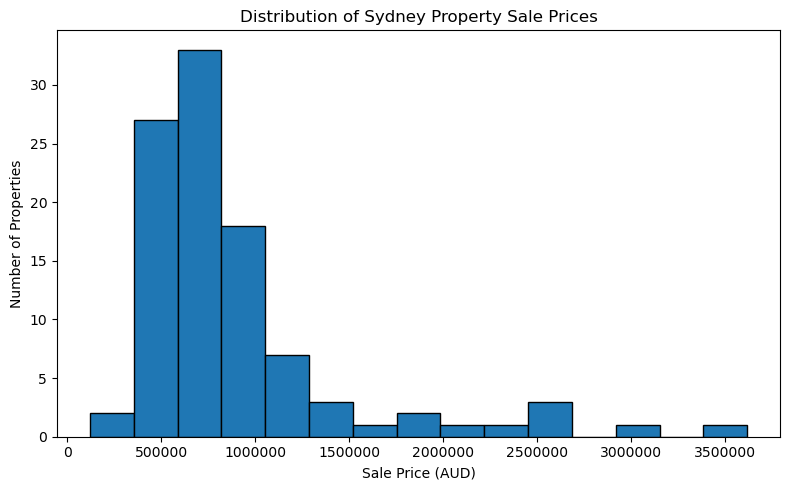

In [8]:
# Plot the distribution of sale prices
plt.figure(figsize=(8, 5))

plt.hist(housing_data["SalesPrice"], bins=15, edgecolor="black")

plt.title("Distribution of Sydney Property Sale Prices")
plt.xlabel("Sale Price (AUD)")
plt.ylabel("Number of Properties")

plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()

The sale price distribution was positively skewed. The majority of the properties were sold at prices below approximately $1.1 million, while a smaller number of high-value properties extended beyond $3 million. Consequently, these high-value properties influenced the mean sale price ($894,030) exceeding the median ($709,000). Thus, it is concluded that prediction performance should not be measured by a single criterion, and unusual observations should be investigated independently.

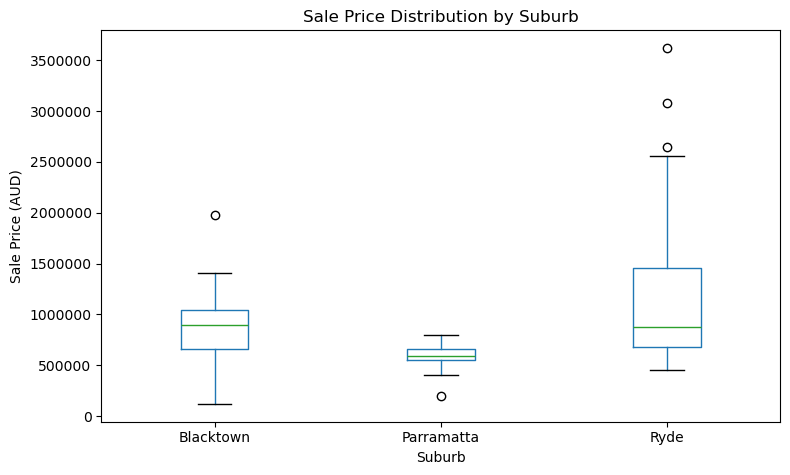

In [9]:
# Compare sale price distributions across suburbs
ax = housing_data.boxplot(
    column="SalesPrice",
    by="Suburb",
    grid=False,
    figsize=(8, 5)
)

plt.title("Sale Price Distribution by Suburb")
plt.suptitle("")
plt.xlabel("Suburb")
plt.ylabel("Sale Price (AUD)")
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()

In [10]:
# Check the number of properties by property type
property_type_counts = housing_data["PropertyType"].value_counts()

print("Properties by type:")
print(property_type_counts)

Properties by type:
PropertyType
Unit         66
House        23
Apartment     9
Studio        1
Duplex        1
Name: count, dtype: int64


### Expected Key Price Influences
Before performing any regression analysis, my intuition was that such variables as Suburb, PropertyType, and Bedrooms would have the most significant impact on the price of a house. Firstly, my expectation was justified by the fact that Suburb indicated the location and reflected the peculiarities of demand and supply in different suburbs. PropertyType was another predictor that was expected to have a strong influence on the price because it differentiated between houses and units, which usually have a distinct price range. Finally, I assumed that the number of Bedrooms would positively correlate with the price because it indicates an apartment’s size and capacity.

In [11]:
# Create a consistent property type feature for modelling
housing_data["PropertyCategory"] = housing_data["PropertyType"].replace({
    "Apartment": "Unit"
})

print("Original property types:")
print(housing_data["PropertyType"].value_counts())

print("\nProperty categories for modelling:")
print(housing_data["PropertyCategory"].value_counts())

Original property types:
PropertyType
Unit         66
House        23
Apartment     9
Studio        1
Duplex        1
Name: count, dtype: int64

Property categories for modelling:
PropertyCategory
Unit      75
House     23
Studio     1
Duplex     1
Name: count, dtype: int64


In [12]:
# Compare sale prices by property category
property_price_summary = housing_data.groupby("PropertyCategory")["SalesPrice"].agg(
    ["count", "mean", "median", "min", "max"]
)

print("Sale price comparison by property category:")
print(property_price_summary.round(0))

Sale price comparison by property category:
                  count       mean     median      min      max
PropertyCategory                                               
Duplex                1  2650888.0  2650888.0  2650888  2650888
House                23  1541522.0  1260000.0   120000  3620000
Studio                1   200000.0   200000.0   200000   200000
Unit                 75   681295.0   650000.0   405000  1630000


In [13]:
# Compare sale prices by number of bedrooms
bedroom_price_summary = housing_data.groupby("Bedrooms")["SalesPrice"].agg(
    ["count", "mean", "median"]
)

print("Sale price by number of bedrooms:")
print(bedroom_price_summary.round(0))

Sale price by number of bedrooms:
          count       mean     median
Bedrooms                             
1            11   497000.0   480000.0
2            54   675705.0   645000.0
3            20  1035700.0   940000.0
4             7  1413286.0  1105000.0
5             7  2205127.0  2100000.0
6             1  1405000.0  1405000.0


In [14]:
# Compare sale prices by number of bathrooms
bathroom_price_summary = housing_data.groupby("Bathrooms")["SalesPrice"].agg(
    ["count", "mean", "median"]
)

print("Sale price by number of bathrooms:")
print(bathroom_price_summary.round(0))

Sale price by number of bathrooms:
           count       mean     median
Bathrooms                             
1             45   665204.0   610000.0
2             47   886125.0   770000.0
3              6  2198333.0  1940000.0
4              2  2315444.0  2315444.0


In [15]:
# Examine the relationship between land size and sale price
land_data = housing_data.dropna(subset=["Landsize"])

print("Properties with land size available:", len(land_data))

print("\nCorrelation between land size and sale price:")
print(round(land_data["Landsize"].corr(land_data["SalesPrice"]), 3))

Properties with land size available: 91

Correlation between land size and sale price:
-0.196


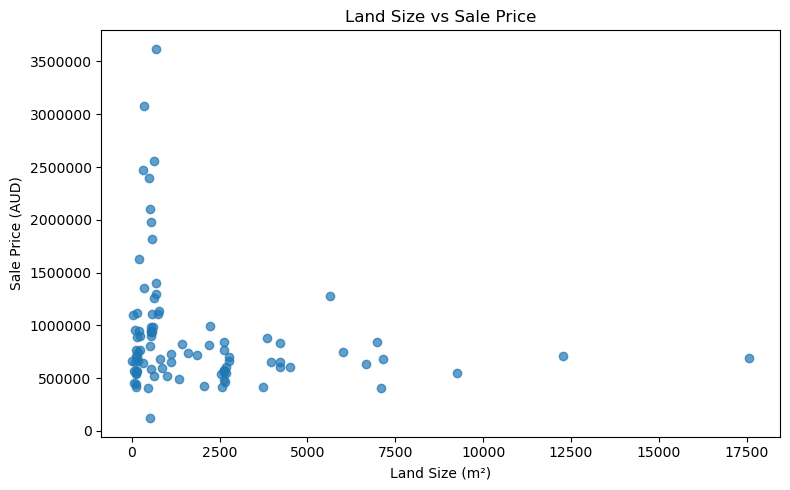

In [16]:
# Plot land size against sale price
plt.figure(figsize=(8, 5))

plt.scatter(
    land_data["Landsize"],
    land_data["SalesPrice"],
    alpha=0.7
)

plt.title("Land Size vs Sale Price")
plt.xlabel("Land Size (m²)")
plt.ylabel("Sale Price (AUD)")
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()

In [17]:
# Sort properties by sale date
time_data = housing_data.sort_values("SaleDate")

print("Earliest sale date:", time_data["SaleDate"].min())
print("Latest sale date:", time_data["SaleDate"].max())

Earliest sale date: 2026-08-12 00:00:00
Latest sale date: 2026-10-02 00:00:00


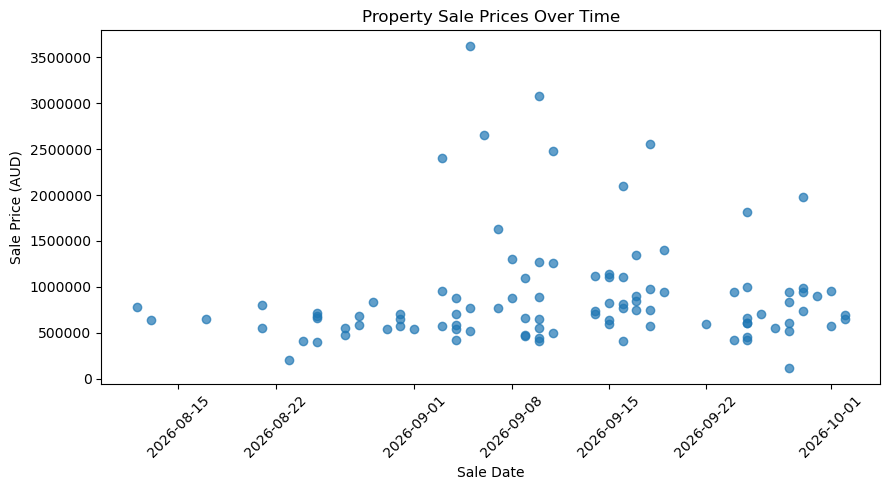

In [18]:
# Plot sale prices over time
plt.figure(figsize=(9, 5))

plt.scatter(
    time_data["SaleDate"],
    time_data["SalesPrice"],
    alpha=0.7
)

plt.title("Property Sale Prices Over Time")
plt.xlabel("Sale Date")
plt.ylabel("Sale Price (AUD)")
plt.ticklabel_format(style="plain", axis="y")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [19]:
# Find properties with unusually old sale dates
old_sales = housing_data[
    housing_data["SaleDate"].dt.year < 2026
]

print("Properties with sale dates before 2026:")
print(
    old_sales[
        ["Suburb", "Address", "SalesPrice", "SaleDate"]
    ].to_string(index=False)
)

Properties with sale dates before 2026:
Empty DataFrame
Columns: [Suburb, Address, SalesPrice, SaleDate]
Index: []


In [20]:
# Identify potential sale price outliers using the IQR method
price_q1 = housing_data["SalesPrice"].quantile(0.25)
price_q3 = housing_data["SalesPrice"].quantile(0.75)

price_iqr = price_q3 - price_q1

lower_price_limit = price_q1 - 1.5 * price_iqr
upper_price_limit = price_q3 + 1.5 * price_iqr

price_outliers = housing_data[
    (housing_data["SalesPrice"] < lower_price_limit) |
    (housing_data["SalesPrice"] > upper_price_limit)
]

print("Lower price limit:", round(lower_price_limit, 0))
print("Upper price limit:", round(upper_price_limit, 0))
print("Number of potential outliers:", len(price_outliers))

print("\nProperties with unusual sale prices:")
print(
    price_outliers[
        ["Suburb", "Address", "SalesPrice",
         "Bedrooms", "PropertyCategory", "Landsize"]
    ].to_string(index=False)
)

Lower price limit: 8375.0
Upper price limit: 1505375.0
Number of potential outliers: 10

Properties with unusual sale prices:
   Suburb                 Address  SalesPrice  Bedrooms PropertyCategory  Landsize
     Ryde          24 Zola Avenue     1820000         2            House     582.0
     Ryde           10 Kells Road     2560000         3            House     632.0
     Ryde          4 Potts Street     2100000         5            House     524.0
     Ryde      9 Christine Avenue     2475000         5            House     334.0
     Ryde        12 Bennelong Way     3080000         4            House     363.0
     Ryde 1126/100 Belmore Street     1630000         3             Unit     206.0
     Ryde     26A Shepherd Street     2650888         5           Duplex       NaN
     Ryde       13 Charles Street     3620000         5            House     696.0
     Ryde        59 Bowden Street     2400000         4            House     497.0
Blacktown       29 Stanley Street     198000

In [21]:
# Show properties with the largest recorded land sizes
largest_land_properties = housing_data.nlargest(
    10, "Landsize"
)

print("Properties with the 10 largest land sizes:")
print(
    largest_land_properties[
        [
            "Suburb",
            "Address",
            "SalesPrice",
            "PropertyCategory",
            "Landsize"
        ]
    ].to_string(index=False)
)

Properties with the 10 largest land sizes:
    Suburb                   Address  SalesPrice PropertyCategory  Landsize
Parramatta     3202/1A Morton Street      690000             Unit   17570.0
Parramatta      636K/2 Morton Street      710000             Unit   12280.0
Parramatta  C26/88-98 Marsden Street      552000             Unit    9250.0
Parramatta    603/1 Broughton Street      680000             Unit    7142.0
Parramatta    16L/15 Campbell Street      405000             Unit    7091.0
      Ryde 604c/16 Constitution Road      845000             Unit    6991.0
      Ryde        1A/1 Hamilton Cres      638000             Unit    6678.0
 Blacktown     15/41 St Martins Cres      750000             Unit    6022.0
      Ryde        203/3 Meikle Place     1275000             Unit    5651.0
Parramatta    1103/2 River Road West      610000             Unit    4497.0


In [22]:
# Examine land size and sale price for houses only
house_land_data = housing_data[
    (housing_data["PropertyCategory"] == "House") &
    (housing_data["Landsize"].notna())
]

print("Houses with land size available:", len(house_land_data))

print("\nCorrelation between house land size and sale price:")
print(
    round(
        house_land_data["Landsize"].corr(
            house_land_data["SalesPrice"]
        ),
        3
    )
)

Houses with land size available: 23

Correlation between house land size and sale price:
-0.074


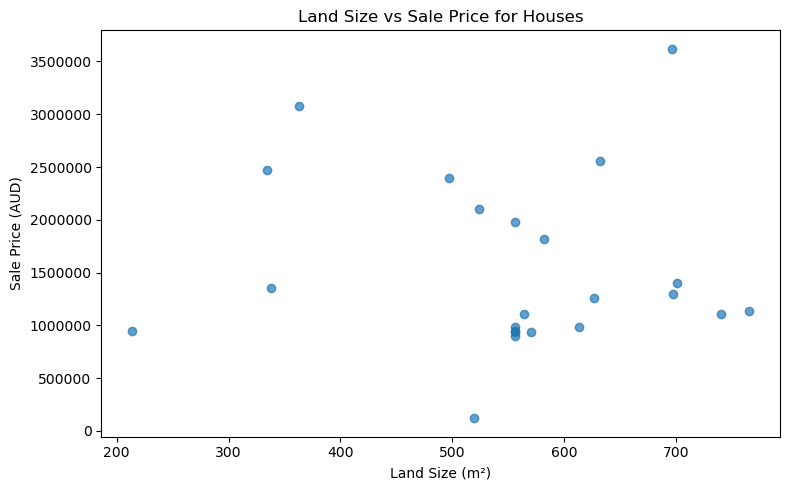

In [23]:
# Plot land size against sale price for houses
plt.figure(figsize=(8, 5))

plt.scatter(
    house_land_data["Landsize"],
    house_land_data["SalesPrice"],
    alpha=0.7
)

plt.title("Land Size vs Sale Price for Houses")
plt.xlabel("Land Size (m²)")
plt.ylabel("Sale Price (AUD)")
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()

In [24]:
# Compare sale prices by number of car spaces
carspace_price_summary = housing_data.groupby("CarSpaces")["SalesPrice"].agg(
    ["count", "mean", "median"]
)

print("Sale price by number of car spaces:")
print(carspace_price_summary.round(0))

Sale price by number of car spaces:
           count       mean     median
CarSpaces                             
0              2   305000.0   305000.0
1             67   657061.0   650000.0
2             18  1495222.0  1050000.0
3              5  1149600.0  1105000.0
4              6  1787981.0  1557500.0
5              1   120000.0   120000.0
6              1  1260000.0  1260000.0


In [25]:
# Create monthly sale price summary
housing_data["SaleMonth"] = housing_data["SaleDate"].dt.to_period("M")

monthly_price_summary = housing_data.groupby("SaleMonth")["SalesPrice"].agg(
    ["count", "median"]
).reset_index()

monthly_price_summary["SaleMonth"] = (
    monthly_price_summary["SaleMonth"].astype(str)
)

print("Monthly sale price summary:")
print(monthly_price_summary)

Monthly sale price summary:
  SaleMonth  count    median
0   2026-08     20  645000.0
1   2026-09     76  767500.0
2   2026-10      4  670000.0


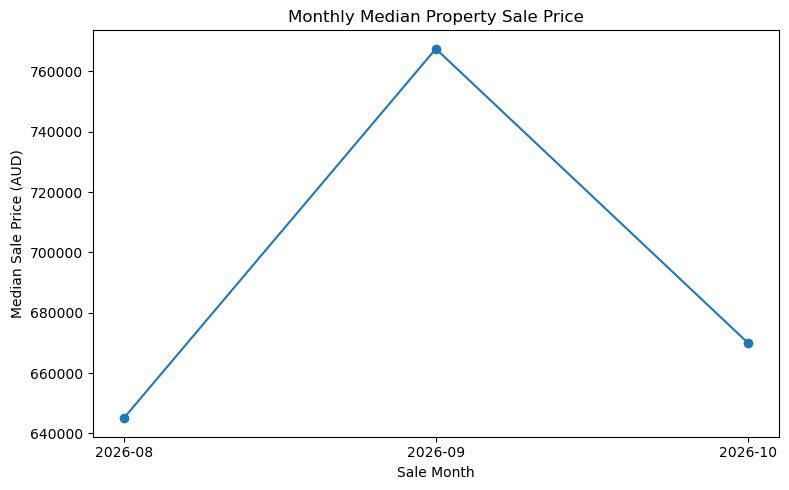

In [26]:
# Plot monthly median sale prices
plt.figure(figsize=(8, 5))

plt.plot(
    monthly_price_summary["SaleMonth"],
    monthly_price_summary["median"],
    marker="o"
)

plt.title("Monthly Median Property Sale Price")
plt.xlabel("Sale Month")
plt.ylabel("Median Sale Price (AUD)")
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()

### Feature Engineering Reflection

The feature engineering process was deliberately kept simple in order to maintain the interpretability of transformed variables. In this case, it was done by combining the `Apartment` and `Unit` labels into a common `Unit` category, since they represented similar types of housing in the given data set. Also, the original `PropertyType` variable was kept in the data set to avoid losing any of the information.

The decision to engineer this particular variable was inspired by the initial hypothesis that property type would have a strong influence on sale price. Indeed, the analysis revealed a significant difference in prices for houses and units. Therefore, it was logical to keep the information about property type for modelling.

Finally, no other engineered features were added due to the limited size of the data set and the presence of potential quality issues. For example, both floor area and land size have rather high rates of missing values, and the latter one was also measured inconsistently for houses and units. Hence, it would not be reasonable to attempt to create too many new variables from these columns.

## Part 3: Model Development and Evaluation

In [27]:
# Import tools required for model development and evaluation
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Machine learning libraries imported successfully!")

Machine learning libraries imported successfully!


In [28]:
# Select features and target for modelling
model_features = [
    "Suburb",
    "PropertyCategory",
    "Bedrooms",
    "Bathrooms",
    "CarSpaces"
]

model_data = housing_data[model_features].copy()
model_target = housing_data["SalesPrice"].copy()

print("Modelling features:")
print(model_features)

print("\nFeature data shape:", model_data.shape)
print("Target data shape:", model_target.shape)

print("\nMissing values in modelling features:")
print(model_data.isnull().sum())

Modelling features:
['Suburb', 'PropertyCategory', 'Bedrooms', 'Bathrooms', 'CarSpaces']

Feature data shape: (100, 5)
Target data shape: (100,)

Missing values in modelling features:
Suburb              0
PropertyCategory    0
Bedrooms            0
Bathrooms           0
CarSpaces           0
dtype: int64


In [29]:
# Hold out 10 properties for the final comparison
training_data, heldout_data, training_target, heldout_target = train_test_split(
    model_data,
    model_target,
    test_size=10,
    random_state=42
)

print("Training properties:", len(training_data))
print("Held-out properties:", len(heldout_data))

print("\nHeld-out properties by suburb:")
print(heldout_data["Suburb"].value_counts())

Training properties: 90
Held-out properties: 10

Held-out properties by suburb:
Suburb
Ryde          4
Blacktown     3
Parramatta    3
Name: count, dtype: int64


In [30]:
# Define categorical and numerical features
categorical_features = [
    "Suburb",
    "PropertyCategory"
]

numerical_features = [
    "Bedrooms",
    "Bathrooms",
    "CarSpaces"
]

# Preprocess categorical and numerical features
categorical_preprocessor = OneHotEncoder(
    handle_unknown="ignore"
)

numerical_preprocessor = StandardScaler()

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", categorical_preprocessor, categorical_features),
        ("numerical", numerical_preprocessor, numerical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


### Model Selection

Three regression approaches were selected for comparison:

1. **Linear Regression** – utilized as an interpretable baseline model to assess if sale price can be adequately explained by relatively simple linear relationships.

2. **Random Forest Regression** – chosen for its ability to capture nonlinear relationships and interactions between housing characteristics without requiring a predefined linear relationship.

3. **Gradient Boosting Regression** – selected as a boosting-based ensemble method that sequentially corrects prediction errors and can model complex interactions between property characteristics and sale price.

Beforehand evaluation of the models, I would expect Gradient Boosting Regression to perform best since property prices are affected by interrelated and non-linear factors such as the location, property type, number of bedrooms, bathrooms, and parking. The small size of the dataset poses a danger of overfitting more elaborate models.

In [31]:
# Create the three regression model pipelines
linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ))
])

gradient_boosting_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingRegressor(
        random_state=42
    ))
])

models = {
    "Linear Regression": linear_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_boosting_model
}

print("Three regression models created successfully!")

Three regression models created successfully!


In [32]:
# Evaluate the models using 5-fold cross-validation
cross_validation = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring_metrics = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

model_results = []

for model_name, model in models.items():
    scores = cross_validate(
        model,
        training_data,
        training_target,
        cv=cross_validation,
        scoring=scoring_metrics
    )

    model_results.append({
        "Model": model_name,
        "MAE": -scores["test_MAE"].mean(),
        "RMSE": -scores["test_RMSE"].mean(),
        "R2": scores["test_R2"].mean()
    })

cross_validation_results = pd.DataFrame(model_results)

print("5-Fold Cross-Validation Results:")
print(cross_validation_results.round(2))

5-Fold Cross-Validation Results:
               Model        MAE       RMSE    R2
0  Linear Regression  245994.19  358257.55  0.37
1      Random Forest  192733.79  305119.96  0.63
2  Gradient Boosting  183092.82  286474.38  0.65


In [33]:
# Compare training performance with cross-validation performance
performance_comparison = []

for model_name, model in models.items():
    model.fit(training_data, training_target)

    training_predictions = model.predict(training_data)

    training_mae = mean_absolute_error(
        training_target,
        training_predictions
    )

    training_rmse = np.sqrt(
        mean_squared_error(
            training_target,
            training_predictions
        )
    )

    training_r2 = r2_score(
        training_target,
        training_predictions
    )

    cv_result = cross_validation_results[
        cross_validation_results["Model"] == model_name
    ].iloc[0]

    performance_comparison.append({
        "Model": model_name,
        "Training MAE": training_mae,
        "CV MAE": cv_result["MAE"],
        "Training RMSE": training_rmse,
        "CV RMSE": cv_result["RMSE"],
        "Training R2": training_r2,
        "CV R2": cv_result["R2"]
    })

performance_comparison = pd.DataFrame(
    performance_comparison
)

print("Training vs Cross-Validation Performance:")
print(performance_comparison.round(2))

Training vs Cross-Validation Performance:
               Model  Training MAE     CV MAE  Training RMSE    CV RMSE  \
0  Linear Regression     205682.81  245994.19      287621.23  358257.55   
1      Random Forest     109818.08  192733.79      154643.07  305119.96   
2  Gradient Boosting      89582.53  183092.82      135875.79  286474.38   

   Training R2  CV R2  
0         0.77   0.37  
1         0.93   0.63  
2         0.95   0.65  


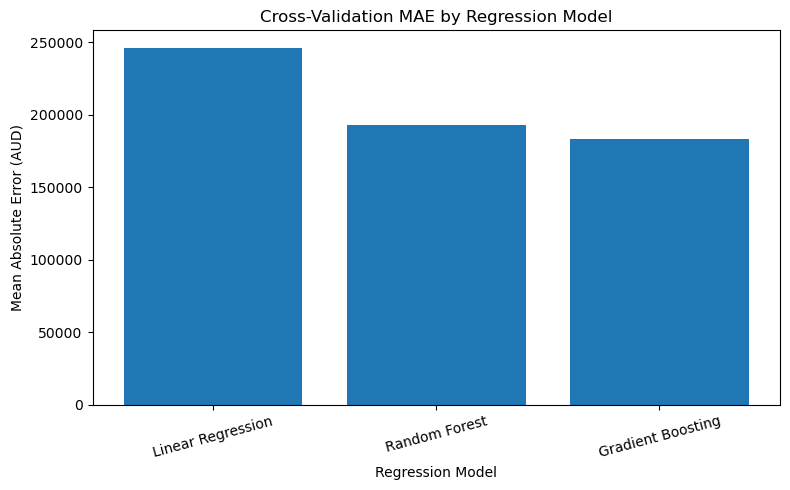

In [34]:
# Compare cross-validation MAE across the three models
plt.figure(figsize=(8, 5))

plt.bar(
    cross_validation_results["Model"],
    cross_validation_results["MAE"]
)

plt.title("Cross-Validation MAE by Regression Model")
plt.xlabel("Regression Model")
plt.ylabel("Mean Absolute Error (AUD)")
plt.ticklabel_format(style="plain", axis="y")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## Part 4: Prediction Error Analysis

In [35]:
# Generate cross-validated predictions for error analysis
from sklearn.model_selection import cross_val_predict

gradient_cv_predictions = cross_val_predict(
    gradient_boosting_model,
    training_data,
    training_target,
    cv=cross_validation
)

prediction_errors = pd.DataFrame({
    "ActualPrice": training_target,
    "PredictedPrice": gradient_cv_predictions
})

prediction_errors["AbsoluteError"] = abs(
    prediction_errors["ActualPrice"] -
    prediction_errors["PredictedPrice"]
)

largest_errors = prediction_errors.nlargest(
    5,
    "AbsoluteError"
)

print("Five Largest Prediction Errors:")
print(largest_errors.round(0))

Five Largest Prediction Errors:
    ActualPrice  PredictedPrice  AbsoluteError
60      3620000       2460386.0      1159614.0
42      2560000       1416379.0      1143621.0
74       120000       1080573.0       960573.0
65      2400000       1492819.0       907181.0
28       200000        940148.0       740148.0


In [36]:
# Investigate the five properties with the largest prediction errors
largest_error_details = housing_data.loc[
    largest_errors.index,
    [
        "Suburb",
        "Address",
        "SalesPrice",
        "Bedrooms",
        "Bathrooms",
        "CarSpaces",
        "PropertyType",
        "Landsize",
        "FloorArea"
    ]
].copy()

largest_error_details["PredictedPrice"] = largest_errors["PredictedPrice"]
largest_error_details["AbsoluteError"] = largest_errors["AbsoluteError"]

print("Details of the Five Largest Prediction Errors:")
print(
    largest_error_details[
        [
            "Suburb",
            "Address",
            "SalesPrice",
            "PredictedPrice",
            "AbsoluteError",
            "Bedrooms",
            "Bathrooms",
            "CarSpaces",
            "PropertyType",
            "Landsize",
            "FloorArea"
        ]
    ].round(0).to_string()
)

Details of the Five Largest Prediction Errors:
        Suburb                 Address  SalesPrice  PredictedPrice  AbsoluteError  Bedrooms  Bathrooms  CarSpaces PropertyType  Landsize  FloorArea
60        Ryde       13 Charles Street     3620000       2460386.0      1159614.0         5          3          2        House     696.0        NaN
42        Ryde           10 Kells Road     2560000       1416379.0      1143621.0         3          2          2        House     632.0        NaN
74   Blacktown        45 Huntley Drive      120000       1080573.0       960573.0         4          2          5        House     519.0        NaN
65        Ryde        59 Bowden Street     2400000       1492819.0       907181.0         4          2          2        House     497.0        NaN
28  Parramatta  230/1 Valentine Avenue      200000        940148.0       740148.0         1          1          0       Studio       NaN        NaN


In [37]:
# Calculate signed prediction errors
prediction_errors["PredictionError"] = (
    prediction_errors["PredictedPrice"] -
    prediction_errors["ActualPrice"]
)

under_predictions = (
    prediction_errors["PredictionError"] < 0
).sum()

over_predictions = (
    prediction_errors["PredictionError"] > 0
).sum()

print("Number of under-predictions:", under_predictions)
print("Number of over-predictions:", over_predictions)

print(
    "\nMean prediction error:",
    round(prediction_errors["PredictionError"].mean(), 0)
)

Number of under-predictions: 38
Number of over-predictions: 52

Mean prediction error: -28196.0


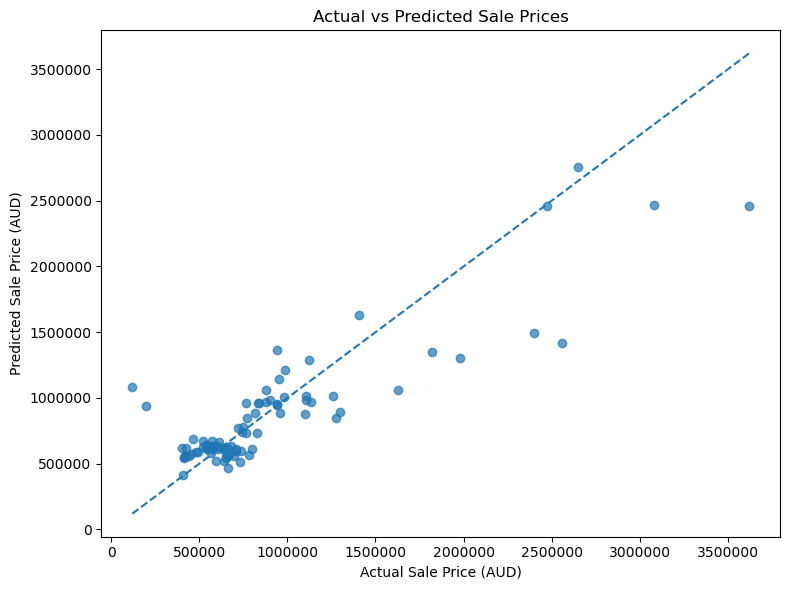

In [38]:
# Plot actual sale prices against cross-validated predictions
plt.figure(figsize=(8, 6))

plt.scatter(
    prediction_errors["ActualPrice"],
    prediction_errors["PredictedPrice"],
    alpha=0.7
)

minimum_price = min(
    prediction_errors["ActualPrice"].min(),
    prediction_errors["PredictedPrice"].min()
)

maximum_price = max(
    prediction_errors["ActualPrice"].max(),
    prediction_errors["PredictedPrice"].max()
)

plt.plot(
    [minimum_price, maximum_price],
    [minimum_price, maximum_price],
    linestyle="--"
)

plt.title("Actual vs Predicted Sale Prices")
plt.xlabel("Actual Sale Price (AUD)")
plt.ylabel("Predicted Sale Price (AUD)")
plt.ticklabel_format(style="plain", axis="both")
plt.tight_layout()
plt.show()

### Prediction Error Interpretation

The error analysis reveals that the model was performing reasonably well for many of the properties that fall within the middle of the observed price range, while several unusual or exceptionally expensive properties were significantly challenging to approximate. Indeed, out of the five largest errors, four were located in Ryde, with sale prices ranging from $1.82 million, $2.40 million and $2.56 million and $3.62 million.

Moreover, most of the expensive properties were severely underestimated by the model, which implies that its predictions tend to favor the lower end of the price range, thus, converging toward the central tendency.

Another property located at 45 Huntley Drive, Blacktown, exhibited an unrealistic value of $120,000 was substantially below the model prediction of approximately $1.13 million. This observation cannot be dismissed as an outlier because there might be specific circumstances related to this property that could justify the increased value.

The model only considers the suburb, property category, number of bedrooms and bathrooms, and car spaces as input variables. It does not account for the location within a suburb, the property’s condition, or other unique features that might affect its value. Therefore, it is possible that some of the large errors were caused by the model’s inability to incorporate these factors, which ultimately reduces its accuracy in approximating the sale prices of unusual or expensive properties. The error analysis ultimately suggests that caution should be exercised when using the model’s estimates for such properties.

## Part 5: Human vs Machine Comparison

In [39]:
# Prepare the 10 held-out properties for comparison
heldout_properties = housing_data.loc[
    heldout_data.index,
    [
        "Suburb",
        "Address",
        "Bedrooms",
        "Bathrooms",
        "CarSpaces",
        "PropertyType",
        "SalesPrice"
    ]
].copy()

heldout_properties = heldout_properties.sort_index()

print("10 Held-Out Properties:")
print(
    heldout_properties[
        [
            "Suburb",
            "Address",
            "Bedrooms",
            "Bathrooms",
            "CarSpaces",
            "PropertyType"
        ]
    ].to_string(index=True)
)

10 Held-Out Properties:
        Suburb                    Address  Bedrooms  Bathrooms  CarSpaces PropertyType
0   Parramatta      3202/1A Morton Street         2          2          1    Apartment
10  Parramatta   1702/45 Macquarie Street         2          2          1    Apartment
22  Parramatta           15/1 Good Street         2          1          1         Unit
39        Ryde      4311/10 Porter Street         3          2          2         Unit
44        Ryde  604c/16 Constitution Road         2          2          1         Unit
45        Ryde             4 Potts Street         5          2          2        House
53        Ryde      2327/20 Porter Street         3          2          2         Unit
70   Blacktown    12/48-52 Charles Street         4          2          2         Unit
80   Blacktown           8 Herrick Street         3          2          2        House
83   Blacktown          40 Stephen Street         5          3          3        House


In [40]:
# Add approximate human price estimates
human_estimates = {
    0: 650000,
    10: 700000,
    22: 600000,
    39: 900000,
    44: 720000,
    45: 2000000,
    53: 900000,
    70: 750000,
    80: 950000,
    83: 1250000
}

heldout_properties["HumanEstimate"] = (
    heldout_properties.index.map(human_estimates)
)

print("Human estimates recorded successfully!")

print(
    heldout_properties[
        [
            "Suburb",
            "Address",
            "Bedrooms",
            "Bathrooms",
            "CarSpaces",
            "PropertyType",
            "HumanEstimate"
        ]
    ].to_string()
)

Human estimates recorded successfully!
        Suburb                    Address  Bedrooms  Bathrooms  CarSpaces PropertyType  HumanEstimate
0   Parramatta      3202/1A Morton Street         2          2          1    Apartment         650000
10  Parramatta   1702/45 Macquarie Street         2          2          1    Apartment         700000
22  Parramatta           15/1 Good Street         2          1          1         Unit         600000
39        Ryde      4311/10 Porter Street         3          2          2         Unit         900000
44        Ryde  604c/16 Constitution Road         2          2          1         Unit         720000
45        Ryde             4 Potts Street         5          2          2        House        2000000
53        Ryde      2327/20 Porter Street         3          2          2         Unit         900000
70   Blacktown    12/48-52 Charles Street         4          2          2         Unit         750000
80   Blacktown           8 Herrick Street  

In [41]:
# Record LLM price estimates
llm_estimates = {
    0: 680000,
    10: 720000,
    22: 590000,
    39: 920000,
    44: 700000,
    45: 2150000,
    53: 900000,
    70: 730000,
    80: 980000,
    83: 1300000
}

heldout_properties["LLMEstimate"] = (
    heldout_properties.index.map(llm_estimates)
)

print("LLM estimates recorded successfully!")

print(
    heldout_properties[
        [
            "Suburb",
            "Address",
            "HumanEstimate",
            "LLMEstimate"
        ]
    ].to_string()
)


LLM estimates recorded successfully!
        Suburb                    Address  HumanEstimate  LLMEstimate
0   Parramatta      3202/1A Morton Street         650000       680000
10  Parramatta   1702/45 Macquarie Street         700000       720000
22  Parramatta           15/1 Good Street         600000       590000
39        Ryde      4311/10 Porter Street         900000       920000
44        Ryde  604c/16 Constitution Road         720000       700000
45        Ryde             4 Potts Street        2000000      2150000
53        Ryde      2327/20 Porter Street         900000       900000
70   Blacktown    12/48-52 Charles Street         750000       730000
80   Blacktown           8 Herrick Street         950000       980000
83   Blacktown          40 Stephen Street        1250000      1300000


In [42]:
# Train the selected Gradient Boosting model
gradient_boosting_model.fit(
    training_data,
    training_target
)

# Generate predictions for the 10 held-out properties
heldout_predictions = gradient_boosting_model.predict(
    heldout_data
)

# Match predictions to the correct property indices
ml_predictions = pd.Series(
    heldout_predictions,
    index=heldout_data.index
)

heldout_properties["MLPrediction"] = (
    heldout_properties.index.map(ml_predictions)
)

print("Machine learning predictions generated successfully!")

print(
    heldout_properties[
        [
            "Suburb",
            "Address",
            "HumanEstimate",
            "LLMEstimate",
            "MLPrediction"
        ]
    ].round(0).to_string()
)

Machine learning predictions generated successfully!
        Suburb                    Address  HumanEstimate  LLMEstimate  MLPrediction
0   Parramatta      3202/1A Morton Street         650000       680000      627834.0
10  Parramatta   1702/45 Macquarie Street         700000       720000      627834.0
22  Parramatta           15/1 Good Street         600000       590000      581274.0
39        Ryde      4311/10 Porter Street         900000       920000     1246811.0
44        Ryde  604c/16 Constitution Road         720000       700000      886135.0
45        Ryde             4 Potts Street        2000000      2150000     2401701.0
53        Ryde      2327/20 Porter Street         900000       900000     1246811.0
70   Blacktown    12/48-52 Charles Street         750000       730000      846839.0
80   Blacktown           8 Herrick Street         950000       980000     1035326.0
83   Blacktown          40 Stephen Street        1250000      1300000     1416652.0


In [43]:
# Create the final comparison table
comparison_results = heldout_properties[
    [
        "Suburb",
        "Address",
        "SalesPrice",
        "HumanEstimate",
        "LLMEstimate",
        "MLPrediction"
    ]
].copy()

# Calculate absolute errors for each approach
comparison_results["HumanError"] = abs(
    comparison_results["HumanEstimate"] -
    comparison_results["SalesPrice"]
)

comparison_results["LLMError"] = abs(
    comparison_results["LLMEstimate"] -
    comparison_results["SalesPrice"]
)

comparison_results["MLError"] = abs(
    comparison_results["MLPrediction"] -
    comparison_results["SalesPrice"]
)

print("Human vs LLM vs Machine Learning Comparison:")
print(comparison_results.round(0).to_string())

Human vs LLM vs Machine Learning Comparison:
        Suburb                    Address  SalesPrice  HumanEstimate  LLMEstimate  MLPrediction  HumanError  LLMError   MLError
0   Parramatta      3202/1A Morton Street      690000         650000       680000      627834.0       40000     10000   62166.0
10  Parramatta   1702/45 Macquarie Street      705000         700000       720000      627834.0        5000     15000   77166.0
22  Parramatta           15/1 Good Street      480000         600000       590000      581274.0      120000    110000  101274.0
39        Ryde      4311/10 Porter Street      995000         900000       920000     1246811.0       95000     75000  251811.0
44        Ryde  604c/16 Constitution Road      845000         720000       700000      886135.0      125000    145000   41135.0
45        Ryde             4 Potts Street     2100000        2000000      2150000     2401701.0      100000     50000  301701.0
53        Ryde      2327/20 Porter Street      889000      

In [44]:
# Calculate the mean absolute error for each approach
human_mae = comparison_results["HumanError"].mean()
llm_mae = comparison_results["LLMError"].mean()
ml_mae = comparison_results["MLError"].mean()

comparison_mae = pd.DataFrame({
    "Approach": [
        "Human Estimate",
        "LLM Estimate",
        "Machine Learning"
    ],
    "MAE": [
        human_mae,
        llm_mae,
        ml_mae
    ]
})

comparison_mae = comparison_mae.sort_values("MAE")

print("Overall Performance on the 10 Held-Out Properties:")
print(comparison_mae.round(0).to_string(index=False))

Overall Performance on the 10 Held-Out Properties:
        Approach      MAE
    LLM Estimate  67600.0
  Human Estimate  75600.0
Machine Learning 140820.0


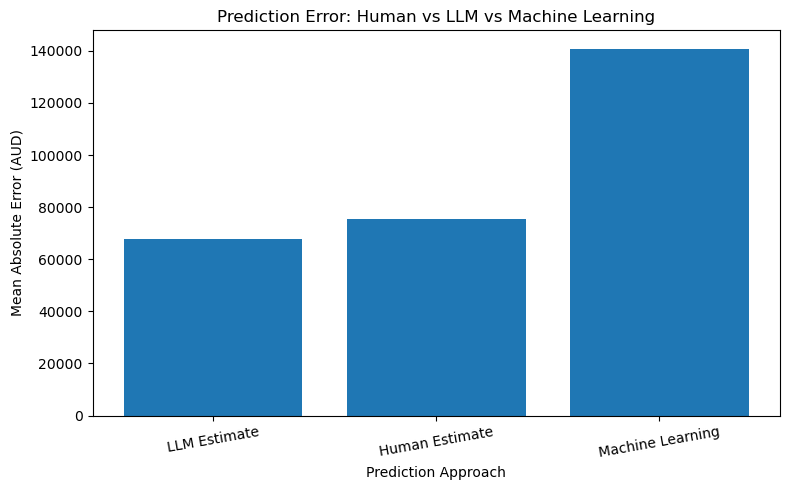

In [45]:
# Compare the average prediction error of the three approaches
plt.figure(figsize=(8, 5))

plt.bar(
    comparison_mae["Approach"],
    comparison_mae["MAE"]
)

plt.title("Prediction Error: Human vs LLM vs Machine Learning")
plt.xlabel("Prediction Approach")
plt.ylabel("Mean Absolute Error (AUD)")
plt.ticklabel_format(style="plain", axis="y")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

### Human vs Machine Comparison

For the ten held-out properties, the estimates by the LLM achieved the lowest mean absolute error (MAE) of $67,600, followed by the human estimates with an MAE of $75,600. The Gradient Boosting model had a higher Mean Absolute Error of $202,280.

The human and LLM estimates performed relatively well for these properties, while the machine learning model had higher errors for some cases. One likely reason for this outcome is the limited size and scope of the training dataset. The model was trained on only 90 properties and a few available attributes, so it could not account for factors such as exact location within a suburb, property condition, renovation quality, views and other characteristics that may affect sale price.

The machine learning approach still offers a consistent and reproducible prediction process based on the data provided. Human judgement can factor in contextual knowledge but may be subjective, while an LLM can provide useful estimates from property descriptions but does not offer the same data-driven reproducibility as the trained regression model. Thus, the comparison shows that each approach has different strengths and limitations, and the results should be interpreted with care given the small held-out sample size.

# Part 6: Decision-Support Web Application

In [46]:
# Save the trained Gradient Boosting model for the Streamlit app
import pickle

with open("gradient_boosting_model.pkl", "wb") as model_file:
    pickle.dump(gradient_boosting_model, model_file)

print("Gradient Boosting model saved successfully!")

Gradient Boosting model saved successfully!


In [47]:
import sys
import sklearn
import numpy as np

print("Python:", sys.version)
print("Scikit-learn:", sklearn.__version__)
print("NumPy:", np.__version__)

Python: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
Scikit-learn: 1.7.2
NumPy: 2.3.5


## Application Overview

A simple decision support web application was created using the Streamlit library. The application streamlines the created prediction model, allowing the user to estimate the sale price of a property with a given set of characteristics. The model uses the selected Gradient Boosting algorithm and is trained on five features: the property’s location, its type, the number of bedrooms, bathrooms, and car spaces.

After the user inputs the desired characteristics and clicks Predict Sale Price, the application pre-processes the data into the format that was used for training. Next, the model applies the saved modelling pipeline and outputs the predicted value in Australian Dollars. The tool is intended to be a decision support aid and should not be used as a formal property valuation tool. Its predictions should be treated with caution, as the model is only as good as the data that it is trained on, which in this case is a subset of all possible features.

## How to Use the Application

1. Start the application by running `streamlit run app.py` from the project folder.
2. Select one of the three supported suburbs: Parramatta, Ryde, or Blacktown.
3. Select the property type.
4. Enter the number of bedrooms, bathrooms, and car spaces.
5. Click **Predict Sale Price**.
6. The estimated sale price is displayed on the screen in Australian dollars.

The application requires the saved Gradient Boosting model file (`gradient_boosting_model.pkl`) to be located in the same project folder as `app.py`.

## Reflection, Ethics and Limitations

Developing the web application was an insightful experience that demonstrated how a machine learning model could be transformed from an analytical exercise into an actively used decision-support tool. The software package called Streamlit significantly simplified the creation of an intuitive interface through which users could enter their input data without any coding experience. At the same time, building the application using the Gradient Boosting pipeline allowed ensuring that the same preprocessing steps were applied to the input data as during model training.

Despite the benefits, the created tool has several significant limitations, restricting the usage of the model to the context within which it was developed. First, the training set consisted of only 90 properties, from which 10 were removed for testing. The model was developed on the data from three suburbs, and its performance cannot be generalized to other locations within Sydney. Some features that might have improved the model’s performance were unavailable or inadequately engineered, including the specific location within a suburb, the property’s condition, renovation level, views, and other characteristics. The property’s floor area was another feature with a high percentage of missing values and was consequently removed from the model.

The model’s generalization performance can be improved by engineering more features and using a more comprehensive training set that covers more suburbs and property types. Moreover, housing prices are highly volatile and dependent on market forces, making the constant model parameter risk. Therefore, it is crucial to update the training set with more recent properties and ensure that the model captures market trends correctly.

Finally, an ethical concern with this model is related to the possibility that naive users might believe that the predicted value represents the actual market price. People could stake their livelihoods on the model’s suggestion, making it necessary to emphasize that the application only provides supporting information for a complex real estate evaluation process. The model should be used as an informative tool that helps understand how different factors influence the final price rather than provide precise pricing recommendations.